# Neuro Monitor for Differentiating Seizures Diseases

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import sklearn

np.random.seed(42)
sys.path.append("..")

from data_loading.pads_loader import load_pads_metadata, filter_pads_cohort, load_all_pads_recordings
from data_loading.epilepsy_loader import load_epilepsy_dataset

In [2]:
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", signal.__name__)
print("sklearn:", sklearn.__version__)

numpy: 2.5.1
pandas: 3.0.2
scipy: scipy.signal
sklearn: 1.9.0


PADS cohort filtering: 268 pure PD subjects (8 excluded for ET comorbidity), 28 pure ET, 79 Healthy

In [3]:
pads_root = os.path.join("..", "data", "pads parkinsons-disease smartwatch dataset-1.0.0")
meta_df = load_pads_metadata(pads_root)
cohort_df = filter_pads_cohort(meta_df)

print("Total PADS subjects:", len(meta_df))
print("Raw condition counts in PADS:")
print(meta_df["condition"].value_counts())

pd_raw_count = (meta_df["condition"] == "Parkinson's").sum()
pd_clean_count = (cohort_df["cohort_label"] == "Parkinsons-like").sum()
excluded_pd_et = pd_raw_count - pd_clean_count
print(f"\nRaw Parkinson's subjects: {pd_raw_count}")
print(f"Excluded PD subjects with documented ET overlap or differential diagnosis: {excluded_pd_et}")
print(f"Retained pure Parkinson's-like subjects: {pd_clean_count}")

print("\nFiltered cohort breakdown:")
print(cohort_df["cohort_label"].value_counts())

et_subjects = cohort_df[cohort_df["cohort_label"] == "ET-like"]["subject_id"].tolist()
print("\nET subject count:", len(et_subjects))
print("ET subject IDs:", et_subjects)

Total PADS subjects: 469
Raw condition counts in PADS:
condition
Parkinson's                 276
Healthy                      79
Other Movement Disorders     60
Essential Tremor             28
Atypical Parkinsonism        15
Multiple Sclerosis           11
Name: count, dtype: int64

Raw Parkinson's subjects: 276
Excluded PD subjects with documented ET overlap or differential diagnosis: 8
Retained pure Parkinson's-like subjects: 268

Filtered cohort breakdown:
cohort_label
Parkinsons-like    268
Normal              79
ET-like             28
Name: count, dtype: int64

ET subject count: 28
ET subject IDs: ['066', '070', '072', '079', '088', '091', '100', '104', '112', '124', '126', '143', '171', '188', '200', '222', '275', '278', '302', '330', '340', '350', '382', '386', '396', '423', '429', '445']


UEA Epilepsy dataset loading: 275 series across 6 participants, archive IDs removed, split into TRAIN and TEST

In [4]:
uea_dir = os.path.join("..", "data", "Epilepsy")
uea_recordings = load_epilepsy_dataset(uea_dir)

uea_df = pd.DataFrame([{
    "series_id": r["series_id"],
    "split": r["split"],
    "task": r["task"],
    "cohort_label": r["cohort_label"],
    "series_length": len(r["data"])
} for r in uea_recordings])

print("Total UEA cases:", len(uea_df))
print("UEA task distribution:")
print(uea_df["task"].value_counts())
print("\nUEA cohort label distribution:")
print(uea_df["cohort_label"].value_counts())
print("\nUEA official subject-disjoint split:")
print(pd.crosstab(uea_df["split"], uea_df["cohort_label"]))
print("\nNote: Participant IDs were removed by the archive creators; intra-split grouping is unknown and the official train/test split is the verified subject-disjoint boundary.")

Total UEA cases: 275
UEA task distribution:
task
WALKING     74
RUNNING     73
EPILEPSY    68
SAWING      60
Name: count, dtype: int64

UEA cohort label distribution:
cohort_label
Normal                      207
Seizure-like (simulated)     68
Name: count, dtype: int64

UEA official subject-disjoint split:
cohort_label  Normal  Seizure-like (simulated)
split                                         
test             104                        34
train            103                        34

Note: Participant IDs were removed by the archive creators; intra-split grouping is unknown and the official train/test split is the verified subject-disjoint boundary.


Raw accelerometer signal inspection across classes with 2-second setup trimming on PADS tremor tasks

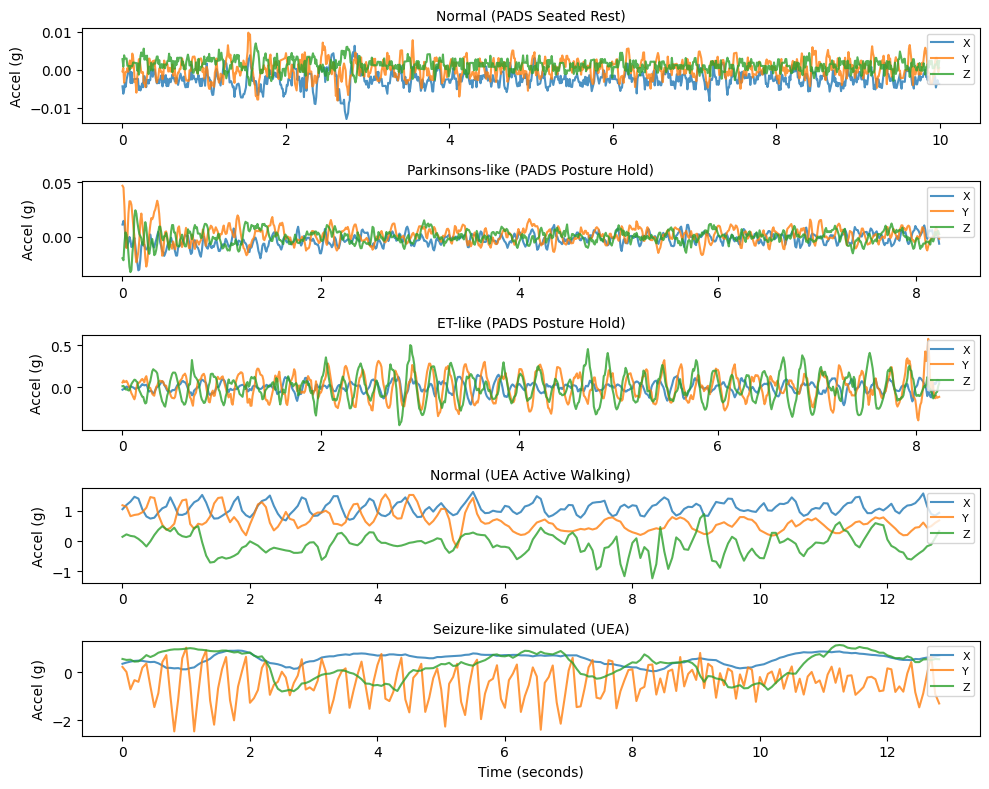

In [5]:
sample_subjects = pd.concat([cohort_df[cohort_df["cohort_label"] == c].head(5) for c in ["Normal", "Parkinsons-like", "ET-like"]])
pads_raw = load_all_pads_recordings(
    pads_root, sample_subjects,
    tasks=["Relaxed", "RelaxedTask", "StretchHold", "LiftHold", "HoldWeight"],
    trim_start_samples=200
)

fig, axes = plt.subplots(5, 1, figsize=(10, 8), sharex=False)
sample_map = {
    "Normal (PADS Seated Rest)": next(r for r in pads_raw if r["cohort_label"] == "Normal" and r["task"] == "Relaxed"),
    "Parkinsons-like (PADS Posture Hold)": next(r for r in pads_raw if r["cohort_label"] == "Parkinsons-like" and r["task"] == "StretchHold"),
    "ET-like (PADS Posture Hold)": next(r for r in pads_raw if r["cohort_label"] == "ET-like" and r["task"] == "StretchHold"),
    "Normal (UEA Active Walking)": next(r for r in uea_recordings if r["task"] == "WALKING"),
    "Seizure-like simulated (UEA)": next(r for r in uea_recordings if r["task"] == "EPILEPSY")
}

for ax, (title, sample) in zip(axes, sample_map.items()):
    data = sample["data"]
    if sample["dataset"] == "PADS":
        sig = data[:1000, 1:4]
        time_axis = np.arange(len(sig)) / 100.0
    else:
        sig = data[:, :3]
        time_axis = np.arange(len(sig)) / 16.0
    ax.plot(time_axis, sig[:, 0], label="X", alpha=0.8)
    ax.plot(time_axis, sig[:, 1], label="Y", alpha=0.8)
    ax.plot(time_axis, sig[:, 2], label="Z", alpha=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Accel (g)")
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.savefig(os.path.join("..", "results", "plots", "raw_signals_comparison.png"))
plt.show()

Class-average PSD per task with 95% confidence bands across Healthy, PD, and ET cohorts

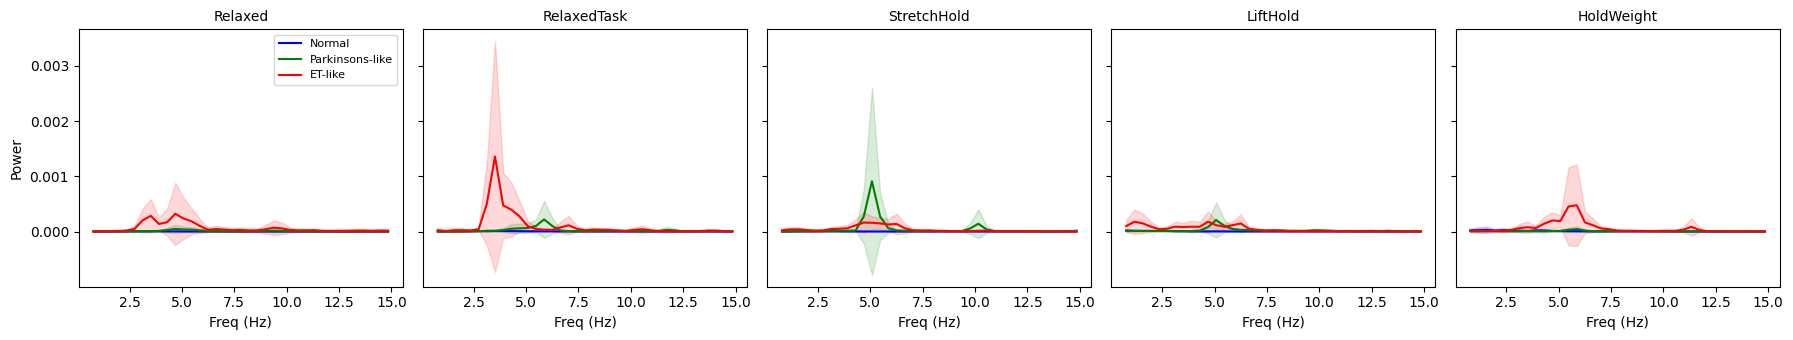

In [6]:
sample_cohort_psd = pd.concat([
    cohort_df[cohort_df["cohort_label"] == "Normal"].head(20),
    cohort_df[cohort_df["cohort_label"] == "Parkinsons-like"].head(20),
    cohort_df[cohort_df["cohort_label"] == "ET-like"]
])
psd_tasks = ["Relaxed", "RelaxedTask", "StretchHold", "LiftHold", "HoldWeight"]
recs_psd = load_all_pads_recordings(pads_root, sample_cohort_psd, tasks=psd_tasks, trim_start_samples=200)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)

for ax_idx, task in enumerate(psd_tasks):
    ax = axes[ax_idx]
    for label, color in [("Normal", "blue"), ("Parkinsons-like", "green"), ("ET-like", "red")]:
        task_recs = [r for r in recs_psd if r["task"] == task and r["cohort_label"] == label]
        psds = []
        for r in task_recs:
            sig = r["data"][:, 1]
            freqs, p = signal.welch(sig, fs=100.0, nperseg=256)
            mask = (freqs >= 0.5) & (freqs <= 15.0)
            psds.append(p[mask])
        psds = np.array(psds)
        freqs_sub = freqs[mask]
        mean_psd = np.mean(psds, axis=0)
        sem_psd = np.std(psds, axis=0) / np.sqrt(max(1, len(psds)))
        ax.plot(freqs_sub, mean_psd, label=label, color=color)
        ax.fill_between(freqs_sub, mean_psd - 1.96*sem_psd, mean_psd + 1.96*sem_psd, color=color, alpha=0.15)
    ax.set_title(task, fontsize=10)
    ax.set_xlabel("Freq (Hz)")
    if ax_idx == 0:
        ax.set_ylabel("Power")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "class_average_psd_per_task.png"))
plt.show()

Acceleration amplitude distribution with separate axes demonstrating gravity presence in UEA versus zero-mean PADS

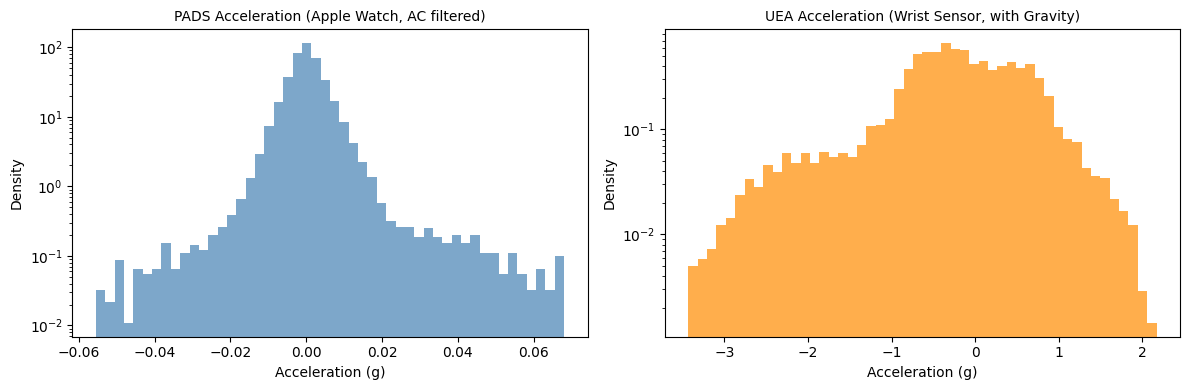

In [7]:
pads_accel_sample = np.concatenate([r["data"][:, 1:4].flatten() for r in pads_raw[:10]])
uea_accel_sample = np.concatenate([r["data"][:, :3].flatten() for r in uea_recordings[:20]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pads_accel_sample, bins=50, density=True, color="steelblue", alpha=0.7)
axes[0].set_title("PADS Acceleration (Apple Watch, AC filtered)", fontsize=10)
axes[0].set_xlabel("Acceleration (g)")
axes[0].set_ylabel("Density")
axes[0].set_yscale("log")

axes[1].hist(uea_accel_sample, bins=50, density=True, color="darkorange", alpha=0.7)
axes[1].set_title("UEA Acceleration (Wrist Sensor, with Gravity)", fontsize=10)
axes[1].set_xlabel("Acceleration (g)")
axes[1].set_ylabel("Density")
axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "amplitude_distribution_comparison.png"))
plt.show()

Dataset inventory summary table

In [8]:
summary_data = [
    {"Dataset": "PADS", "Device": "Apple Watch Series 4", "Rate (Hz)": 100, "Channels": 7, "Subjects": len(cohort_df), "Classes": "Normal, PD-like, ET-like (Tremor tasks)"},
    {"Dataset": "UEA Epilepsy", "Device": "Wrist Accelerometer", "Rate (Hz)": 16, "Channels": 3, "Subjects": "6 (Pool)", "Classes": "Normal, Seizure-like (simulated)"}
]
summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

     Dataset               Device  Rate (Hz)  Channels Subjects                                 Classes
        PADS Apple Watch Series 4        100         7      375 Normal, PD-like, ET-like (Tremor tasks)
UEA Epilepsy  Wrist Accelerometer         16         3 6 (Pool)        Normal, Seizure-like (simulated)
